# Odoo Weekly Sales Forecasting with ARIMA

This notebook converts Odoo daily sales revenue into **weekly sales** and builds a complete **AutoRegressive Integrated Moving Average (ARIMA)** forecasting workflow.

Historical range used:
- Start: **2025-01-06**
- Last known daily observation: **2026-08-07**
- Weekly frequency: **Monday through Sunday**, labelled by the week-ending Sunday
- Last complete week used for modeling: **2026-08-02**

Weekly aggregation is useful here because the daily series contains many zero-sales days and sudden large orders.


## 1. PostgreSQL query to export `daily_sales.csv`

Run this in pgAdmin and export the result as `daily_sales.csv`.

```sql
WITH dates AS (
    SELECT generate_series(
        '2025-01-06'::date,
        '2026-08-07'::date,
        INTERVAL '1 day'
    )::date AS sale_date
),
sales AS (
    SELECT
        (
            date_order AT TIME ZONE 'UTC'
            AT TIME ZONE 'Asia/Kolkata'
        )::date AS sale_date,
        SUM(amount_total) AS daily_sales_total
    FROM sale_order
    WHERE state IN ('sale', 'done')
      AND (
            date_order AT TIME ZONE 'UTC'
            AT TIME ZONE 'Asia/Kolkata'
          )::date >= '2025-01-06'
      AND (
            date_order AT TIME ZONE 'UTC'
            AT TIME ZONE 'Asia/Kolkata'
          )::date <= '2026-08-07'
    GROUP BY 1
)
SELECT
    d.sale_date,
    COALESCE(s.daily_sales_total, 0) AS daily_sales_total
FROM dates d
LEFT JOIN sales s ON d.sale_date = s.sale_date
ORDER BY d.sale_date;
```


## 2. Install libraries

In [1]:
!pip install pandas numpy matplotlib statsmodels scikit-learn


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## 3. Imports

In [2]:
import warnings
warnings.filterwarnings('ignore')

import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA, ARIMAResults
from sklearn.metrics import mean_absolute_error, mean_squared_error


## 4. Load daily sales

In [4]:
df = pd.read_csv('Johns_daily_sales.csv')
df.head()


,sale_date,daily_sales_total
0,2025-01-06,5796829.52
1,2025-01-07,903355.24
2,2025-01-08,121297.50
3,2025-01-09,0.00
4,2025-01-10,357332.86


## 5. Prepare the daily time series

In [5]:
df['sale_date'] = pd.to_datetime(df['sale_date'])
df = df.sort_values('sale_date').set_index('sale_date')

print('First date:', df.index.min())
print('Last date :', df.index.max())
print('Rows      :', len(df))

df.head()


First date: 2025-01-06 00:00:00
Last date : 2026-08-07 00:00:00
Rows      : 579


,daily_sales_total
sale_date,
2025-01-06,5796829.52
2025-01-07,903355.24
2025-01-08,121297.50
2025-01-09,0.00
2025-01-10,357332.86


## 6. Enforce a complete daily timeline

A missing day is filled with `0`. This is valid only if a missing date really means **no sales happened**.


In [7]:
df = df.asfreq('D')
print('Missing before fill:')
print(df.isnull().sum())

df['daily_sales_total'] = df['daily_sales_total'].fillna(0)

print('Missing after fill:')
print(df.isnull().sum())


Missing before fill:
daily_sales_total    0
dtype: int64
Missing after fill:
daily_sales_total    0
dtype: int64


## 7. Daily-data diagnostics

In [8]:
print(df['daily_sales_total'].describe())
zero_days = (df['daily_sales_total'] == 0).sum()
print('Zero-sales days:', zero_days)
print('Zero-sales percentage:', round(zero_days / len(df) * 100, 2), '%')


count    5.790000e+02
mean     7.111291e+05
std      1.808549e+06
min      0.000000e+00
25%      0.000000e+00
50%      6.024900e+04
75%      5.517437e+05
max      2.184477e+07
Name: daily_sales_total, dtype: float64
Zero-sales days: 205
Zero-sales percentage: 35.41 %


## 8. Plot daily sales

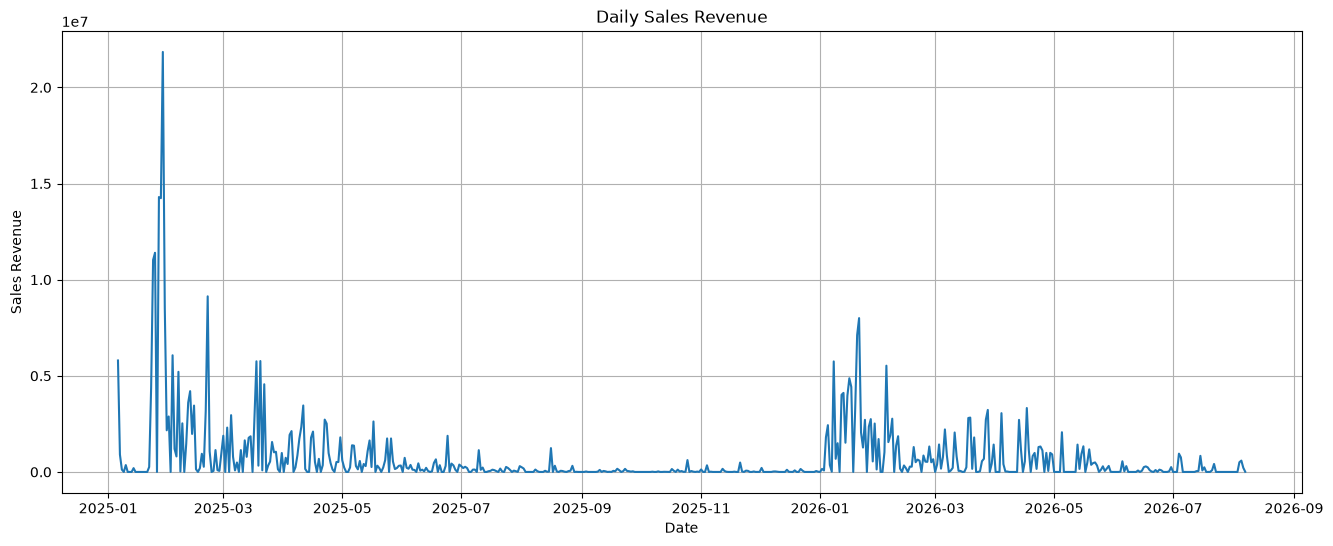

In [9]:
plt.figure(figsize=(16,6))
plt.plot(df.index, df['daily_sales_total'])
plt.title('Daily Sales Revenue')
plt.xlabel('Date')
plt.ylabel('Sales Revenue')
plt.grid(True)
plt.show()


# Weekly aggregation

`resample('W-SUN').sum()` creates Monday-to-Sunday weekly totals labelled by Sunday.


In [10]:
weekly_sales = df['daily_sales_total'].resample('W-SUN').sum()
weekly_sales.head(10)


sale_date
2025-01-12     7178815.12
2025-01-19      198122.40
2025-01-26    27064954.68
2025-02-02    63967214.68
2025-02-09    15832570.52
2025-02-16    14850112.48
2025-02-23    14801949.52
2025-03-02     4170065.72
2025-03-09     6615171.52
2025-03-16     7194944.12
Freq: W-SUN, Name: daily_sales_total, dtype: float64

## 9. Remove the incomplete last week

Your data ends on Friday **2026-08-07**. Therefore the week ending **2026-08-09** is incomplete. We keep only complete weeks through **2026-08-02**.


In [11]:
last_complete_week = pd.Timestamp('2026-08-02')
weekly_sales = weekly_sales.loc[:last_complete_week]

print('First weekly observation:', weekly_sales.index.min())
print('Last complete week      :', weekly_sales.index.max())
print('Complete weeks          :', len(weekly_sales))
weekly_sales.tail()


First weekly observation: 2025-01-12 00:00:00
Last complete week      : 2026-08-02 00:00:00
Complete weeks          : 82


sale_date
2026-07-05    1995826.38
2026-07-12          0.00
2026-07-19    1249108.36
2026-07-26     509215.38
2026-08-02          0.00
Freq: W-SUN, Name: daily_sales_total, dtype: float64

## 10. Weekly summary and plot

count    8.200000e+01
mean     5.005179e+06
std      8.767173e+06
min      0.000000e+00
25%      3.492731e+05
50%      2.030684e+06
75%      6.103794e+06
max      6.396721e+07
Name: daily_sales_total, dtype: float64


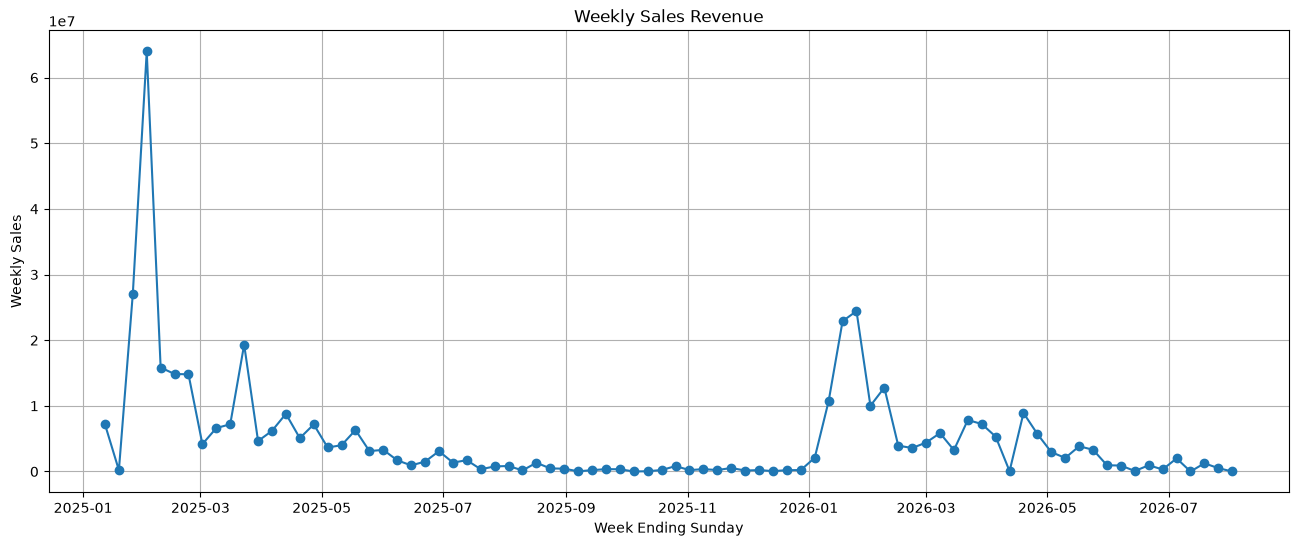

In [12]:
print(weekly_sales.describe())

plt.figure(figsize=(16,6))
plt.plot(weekly_sales.index, weekly_sales.values, marker='o')
plt.title('Weekly Sales Revenue')
plt.xlabel('Week Ending Sunday')
plt.ylabel('Weekly Sales')
plt.grid(True)
plt.show()


## 11. Optional logarithmic view

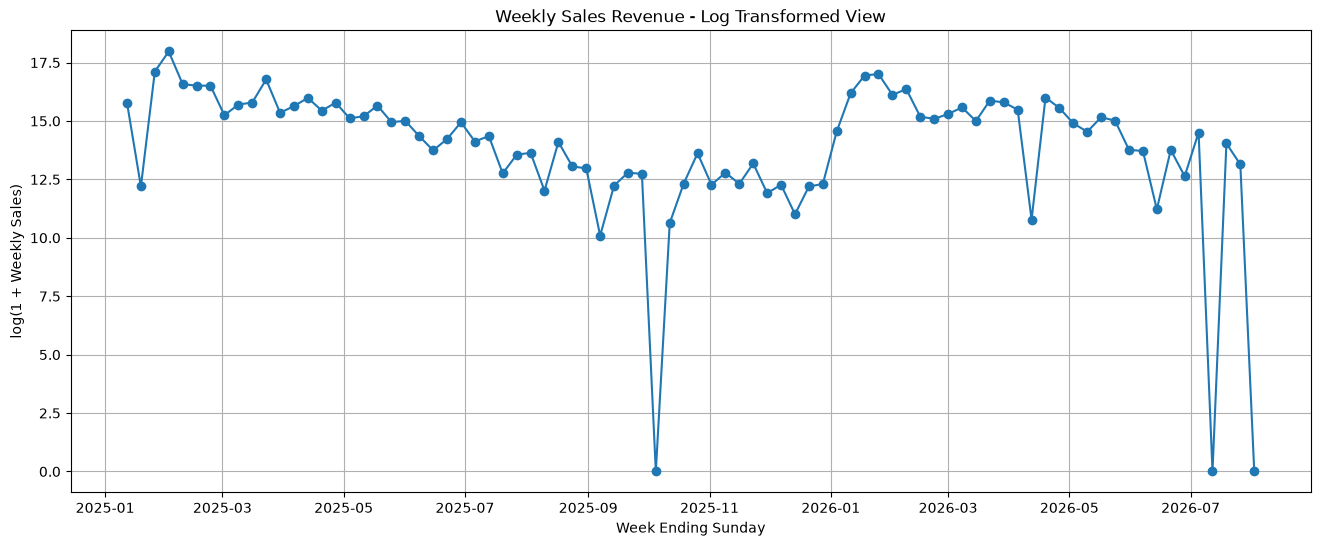

In [13]:
plt.figure(figsize=(16,6))
plt.plot(weekly_sales.index, np.log1p(weekly_sales.values), marker='o')
plt.title('Weekly Sales Revenue - Log Transformed View')
plt.xlabel('Week Ending Sunday')
plt.ylabel('log(1 + Weekly Sales)')
plt.grid(True)
plt.show()


# Train/Test split

- Training: through **2026-05-31**
- Testing: **2026-06-07 through 2026-08-02**


In [14]:
train = weekly_sales.loc[:'2026-05-31']
test = weekly_sales.loc['2026-06-07':'2026-08-02']

print('Training weeks:', len(train))
print('Testing weeks :', len(test))
print('Training:', train.index.min(), '->', train.index.max())
print('Testing :', test.index.min(), '->', test.index.max())


Training weeks: 73
Testing weeks : 9
Training: 2025-01-12 00:00:00 -> 2026-05-31 00:00:00
Testing : 2026-06-07 00:00:00 -> 2026-08-02 00:00:00


## 12. Plot train/test split

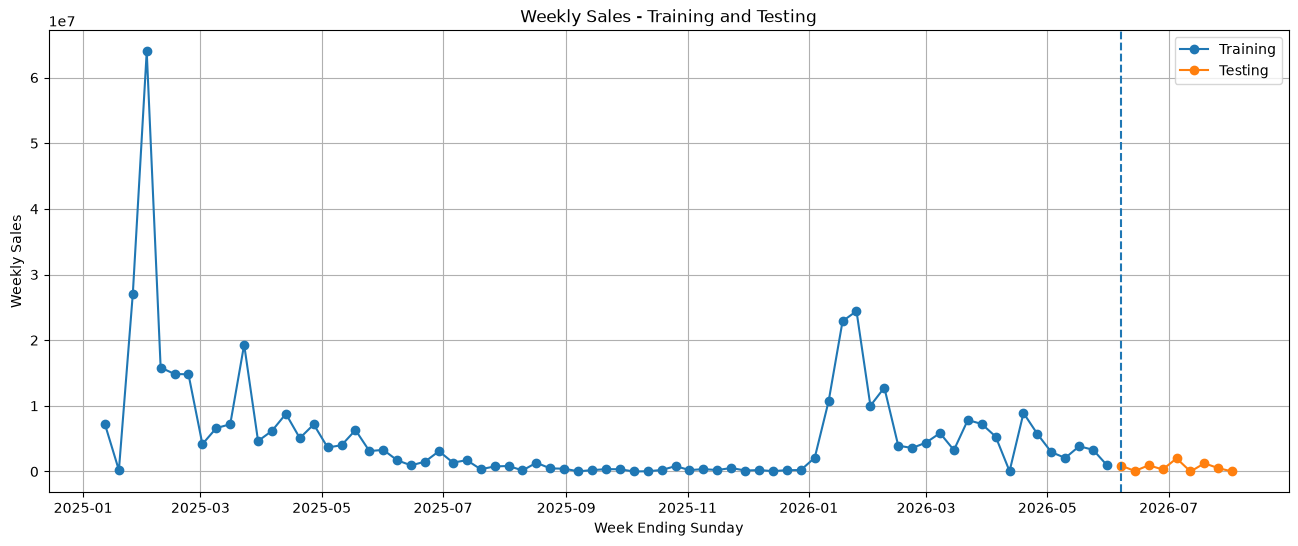

In [15]:
plt.figure(figsize=(16,6))
plt.plot(train.index, train, marker='o', label='Training')
plt.plot(test.index, test, marker='o', label='Testing')
plt.axvline(pd.Timestamp('2026-06-07'), linestyle='--')
plt.title('Weekly Sales - Training and Testing')
plt.xlabel('Week Ending Sunday')
plt.ylabel('Weekly Sales')
plt.legend()
plt.grid(True)
plt.show()


# Evaluation helpers

Metrics:
- **Mean Absolute Error (MAE)**
- **Root Mean Squared Error (RMSE)**
- **Weighted Absolute Percentage Error (WAPE)**

Lower is better.


In [16]:
def wape(actual, predicted):
    actual = np.asarray(actual)
    predicted = np.asarray(predicted)
    denominator = np.sum(np.abs(actual))
    if denominator == 0:
        return np.nan
    return np.sum(np.abs(actual - predicted)) / denominator * 100


def get_metrics(actual, predicted):
    return {
        'MAE': mean_absolute_error(actual, predicted),
        'RMSE': np.sqrt(mean_squared_error(actual, predicted)),
        'WAPE': wape(actual, predicted)
    }


def evaluate_model(actual, predicted, model_name):
    m = get_metrics(actual, predicted)
    print(model_name)
    print('-' * 45)
    print(f"Mean Absolute Error: {m['MAE']:,.2f}")
    print(f"Root Mean Squared Error: {m['RMSE']:,.2f}")
    print(f"Weighted Absolute Percentage Error: {m['WAPE']:.2f}%")


# Baselines

## 13. Last-week naive baseline

In [17]:
last_week_naive = np.repeat(train.iloc[-1], len(test))
evaluate_model(test, last_week_naive, 'Last-Week Naive Baseline')


Last-Week Naive Baseline
---------------------------------------------
Mean Absolute Error: 583,520.87
Root Mean Squared Error: 696,606.05
Weighted Absolute Percentage Error: 87.65%


## 14. Four-week mean baseline

In [18]:
last_4_week_mean = train.tail(4).mean()
four_week_mean_predictions = np.repeat(last_4_week_mean, len(test))

evaluate_model(test, four_week_mean_predictions, 'Four-Week Mean Baseline')


Four-Week Mean Baseline
---------------------------------------------
Mean Absolute Error: 1,876,584.52
Root Mean Squared Error: 1,981,318.88
Weighted Absolute Percentage Error: 281.87%


## 15. Plot baseline forecasts

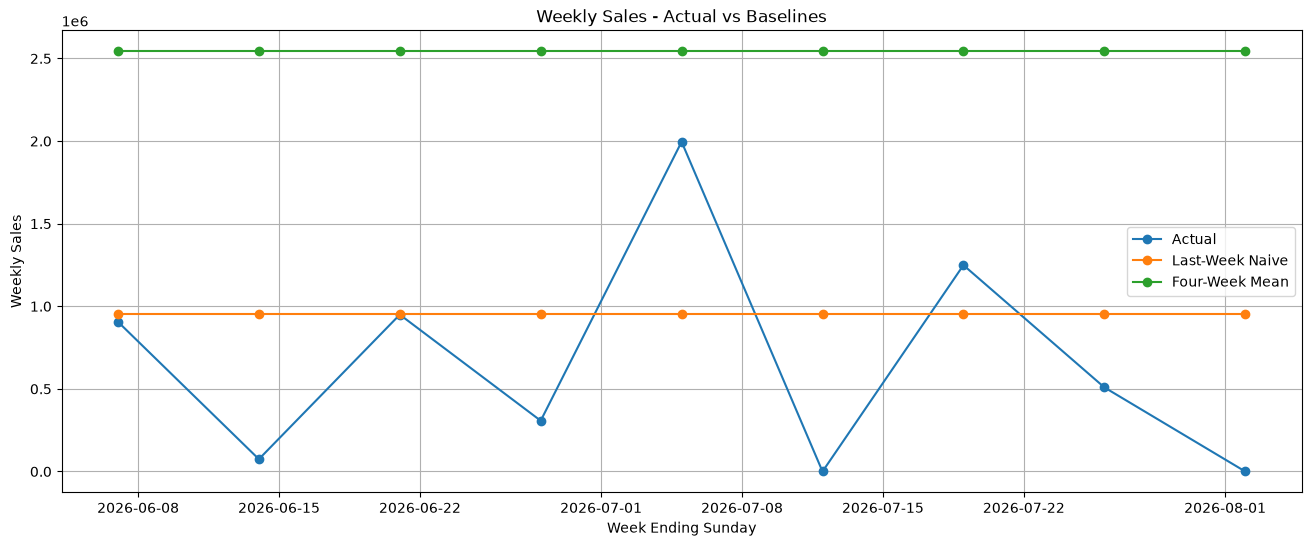

In [19]:
plt.figure(figsize=(16,6))
plt.plot(test.index, test, marker='o', label='Actual')
plt.plot(test.index, last_week_naive, marker='o', label='Last-Week Naive')
plt.plot(test.index, four_week_mean_predictions, marker='o', label='Four-Week Mean')
plt.title('Weekly Sales - Actual vs Baselines')
plt.xlabel('Week Ending Sunday')
plt.ylabel('Weekly Sales')
plt.legend()
plt.grid(True)
plt.show()


# Stationarity

In [20]:
def adf_test(series, name='Series'):
    result = adfuller(series.dropna())
    print(name)
    print('-' * 45)
    print('ADF Statistic:', result[0])
    print('p-value      :', result[1])
    if result[1] <= 0.05:
        print('Interpretation: evidence of stationarity')
    else:
        print('Interpretation: may be non-stationary')
    return result

adf_test(train, 'Original Weekly Training Series')


Original Weekly Training Series
---------------------------------------------
ADF Statistic: -4.640298333269061
p-value      : 0.00010879128850398095
Interpretation: evidence of stationarity


(np.float64(-4.640298333269061),
 np.float64(0.00010879128850398095),
 0,
 72,
 {'1%': np.float64(-3.524624466842421),
  '5%': np.float64(-2.9026070739026064),
  '10%': np.float64(-2.5886785262345677)},
 np.float64(1975.6603793236152))

## 16. First differencing

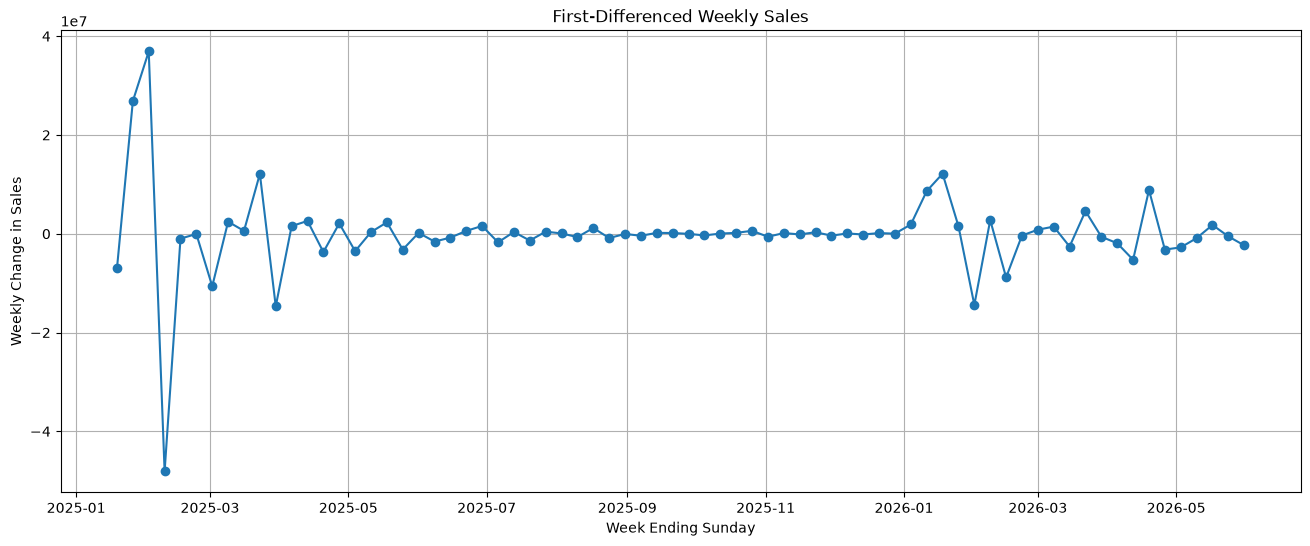

First-Differenced Weekly Training Series
---------------------------------------------
ADF Statistic: -10.316359667159785
p-value      : 3.089882437941612e-18
Interpretation: evidence of stationarity


(np.float64(-10.316359667159785),
 np.float64(3.089882437941612e-18),
 0,
 71,
 {'1%': np.float64(-3.526004646825607),
  '5%': np.float64(-2.9032002348069774),
  '10%': np.float64(-2.5889948363419957)},
 np.float64(1951.4474932481367))

In [21]:
train_diff_1 = train.diff().dropna()

plt.figure(figsize=(16,6))
plt.plot(train_diff_1.index, train_diff_1.values, marker='o')
plt.title('First-Differenced Weekly Sales')
plt.xlabel('Week Ending Sunday')
plt.ylabel('Weekly Change in Sales')
plt.grid(True)
plt.show()

adf_test(train_diff_1, 'First-Differenced Weekly Training Series')


# AutoCorrelation Function and Partial AutoCorrelation Function

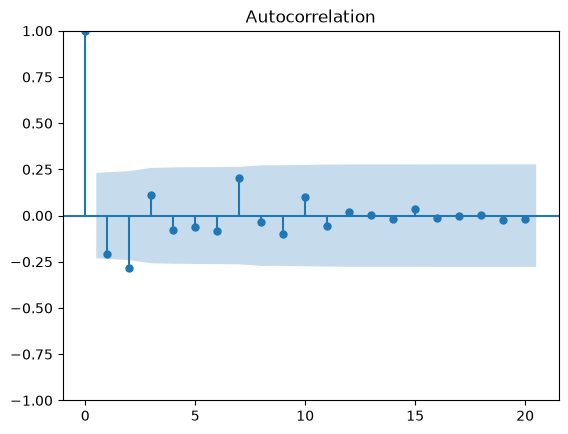

In [22]:
max_lags = min(20, len(train_diff_1) // 2 - 1)
plot_acf(train_diff_1, lags=max_lags)
plt.show()


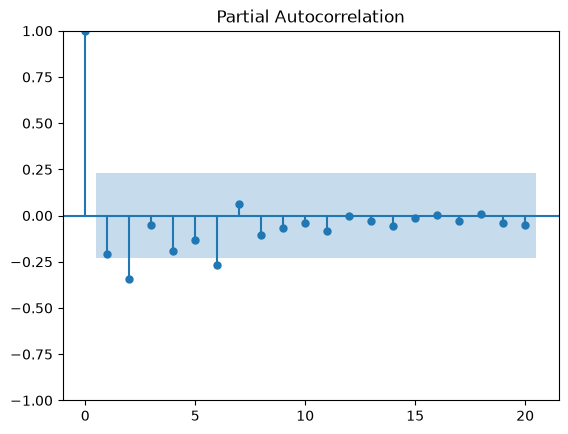

In [23]:
plot_pacf(train_diff_1, lags=max_lags, method='ywm')
plt.show()


# Search ARIMA(p,d,q)

We test:
- `p = 0..4`
- `d = 0..2`
- `q = 0..4`

Models are initially ranked by **Akaike Information Criterion (AIC)**. Final judgment should use out-of-sample forecasting metrics as well.


In [24]:
p_values = range(0,5)
d_values = range(0,3)
q_values = range(0,5)

results = []
for p, d, q in itertools.product(p_values, d_values, q_values):
    try:
        fitted = ARIMA(train, order=(p,d,q)).fit()
        results.append({'p':p, 'd':d, 'q':q, 'AIC':fitted.aic})
    except Exception:
        pass

results_df = pd.DataFrame(results).sort_values('AIC').reset_index(drop=True)
results_df.head(15)


c:\Users\adithyankg\OneDrive\Pictures\statistical_models\.venv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
c:\Users\adithyankg\OneDrive\Pictures\statistical_models\.venv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
c:\Users\adithyankg\OneDrive\Pictures\statistical_models\.venv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
c:\Users\adithyankg\OneDrive\Pictures\statistical_models\.venv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warning

,p,d,q,AIC
0,2,2,0,2500.392884
1,2,1,0,2504.565487
2,0,2,1,2508.861419
3,1,1,0,2508.951351
4,0,1,0,2510.437698
5,1,2,1,2519.874448
6,1,2,0,2522.091548
7,4,2,1,2523.461214
8,2,2,1,2523.996214
9,3,2,1,2525.835627


## 17. Select and fit the best-Akaike-Information-Criterion model

In [25]:
best_row = results_df.iloc[0]
best_p = int(best_row['p'])
best_d = int(best_row['d'])
best_q = int(best_row['q'])

print(f'Best ARIMA order = ({best_p}, {best_d}, {best_q})')
print(f"AIC = {best_row['AIC']:.2f}")

arima_result = ARIMA(train, order=(best_p, best_d, best_q)).fit()
print(arima_result.summary())


Best ARIMA order = (2, 2, 0)
AIC = 2500.39
                               SARIMAX Results                                
Dep. Variable:      daily_sales_total   No. Observations:                   73
Model:                 ARIMA(2, 2, 0)   Log Likelihood               -1247.196
Date:                Mon, 10 Aug 2026   AIC                           2500.393
Time:                        10:04:09   BIC                           2507.181
Sample:                    01-12-2025   HQIC                          2503.092
                         - 05-31-2026                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.7471      0.052    -14.270      0.000      -0.850      -0.644
ar.L2         -0.5426      0.036    -15.162      0.000      -0.613      -0.472
sigma2   

# Multi-step test forecast

In [26]:
forecast_result = arima_result.get_forecast(steps=len(test))
arima_predictions = forecast_result.predicted_mean
arima_predictions.index = test.index
arima_predictions_clipped = arima_predictions.clip(lower=0)

arima_predictions_clipped


sale_date
2026-06-07    1.210199e+06
2026-06-14    5.022529e+05
2026-06-21    0.000000e+00
2026-06-28    0.000000e+00
2026-07-05    0.000000e+00
2026-07-12    0.000000e+00
2026-07-19    0.000000e+00
2026-07-26    0.000000e+00
2026-08-02    0.000000e+00
Freq: W-SUN, Name: predicted_mean, dtype: float64

## 18. Comparison table

In [27]:
comparison = pd.DataFrame({
    'actual': test,
    'last_week_naive': last_week_naive,
    'four_week_mean': four_week_mean_predictions,
    'arima': arima_predictions_clipped
})
comparison


,actual,last_week_naive,four_week_mean,arima
sale_date,,,,
2026-06-07,906025.08,950716.32,2542335.99,1.210199e+06
2026-06-14,74626.68,950716.32,2542335.99,5.022529e+05
2026-06-21,949571.74,950716.32,2542335.99,0.000000e+00
2026-06-28,307389.60,950716.32,2542335.99,0.000000e+00
2026-07-05,1995826.38,950716.32,2542335.99,0.000000e+00
2026-07-12,0.00,950716.32,2542335.99,0.000000e+00
2026-07-19,1249108.36,950716.32,2542335.99,0.000000e+00
2026-07-26,509215.38,950716.32,2542335.99,0.000000e+00
2026-08-02,0.00,950716.32,2542335.99,0.000000e+00


In [45]:
comparison_raw = pd.DataFrame({
    "actual": test,
    "arima_raw": arima_predictions,
    "arima_clipped": arima_predictions_clipped
})

comparison_raw

,actual,arima_raw,arima_clipped
sale_date,,,
2026-06-07,906025.08,1.210199e+06,1.210199e+06
2026-06-14,74626.68,5.022529e+05,5.022529e+05
2026-06-21,949571.74,-9.026621e+05,0.000000e+00
2026-06-28,307389.60,-1.261994e+06,0.000000e+00
2026-07-05,1995826.38,-2.024325e+06,0.000000e+00
2026-07-12,0.00,-3.052868e+06,0.000000e+00
2026-07-19,1249108.36,-3.663877e+06,0.000000e+00
2026-07-26,509215.38,-4.442386e+06,0.000000e+00
2026-08-02,0.00,-5.322293e+06,0.000000e+00


## 19. Evaluate all models

In [28]:
metrics_df = pd.DataFrame([
    get_metrics(test, last_week_naive),
    get_metrics(test, four_week_mean_predictions),
    get_metrics(test, arima_predictions_clipped)
], index=['Last-Week Naive', 'Four-Week Mean', 'ARIMA'])

metrics_df.sort_values('WAPE')


,MAE,RMSE,WAPE
Last-Week Naive,5.835209e+05,6.966061e+05,87.648455
ARIMA,6.381013e+05,8.865950e+05,95.846774
Four-Week Mean,1.876585e+06,1.981319e+06,281.874635


## 20. Plot actual versus forecasts

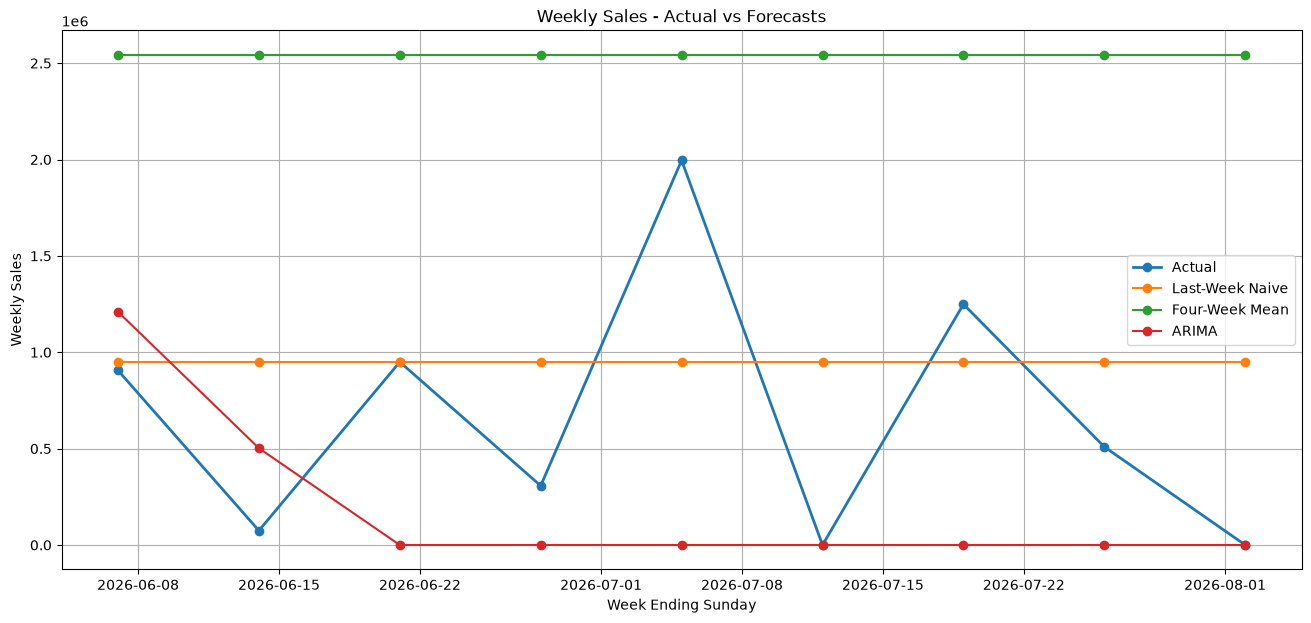

In [29]:
plt.figure(figsize=(16,7))
plt.plot(test.index, test, marker='o', linewidth=2, label='Actual')
plt.plot(test.index, last_week_naive, marker='o', label='Last-Week Naive')
plt.plot(test.index, four_week_mean_predictions, marker='o', label='Four-Week Mean')
plt.plot(test.index, arima_predictions_clipped, marker='o', label='ARIMA')
plt.title('Weekly Sales - Actual vs Forecasts')
plt.xlabel('Week Ending Sunday')
plt.ylabel('Weekly Sales')
plt.legend()
plt.grid(True)
plt.show()


## 21. Confidence intervals

In [30]:
test_confidence = forecast_result.conf_int()
test_confidence.index = test.index
test_confidence.iloc[:,0] = test_confidence.iloc[:,0].clip(lower=0)

test_confidence


,lower daily_sales_total,upper daily_sales_total
sale_date,,
2026-06-07,0.0,1.923135e+07
2026-06-14,0.0,2.939114e+07
2026-06-21,0.0,3.892556e+07
2026-06-28,0.0,5.472715e+07
2026-07-05,0.0,7.033113e+07
2026-07-12,0.0,8.636413e+07
2026-07-19,0.0,1.051636e+08
2026-07-26,0.0,1.245881e+08
2026-08-02,0.0,1.448065e+08


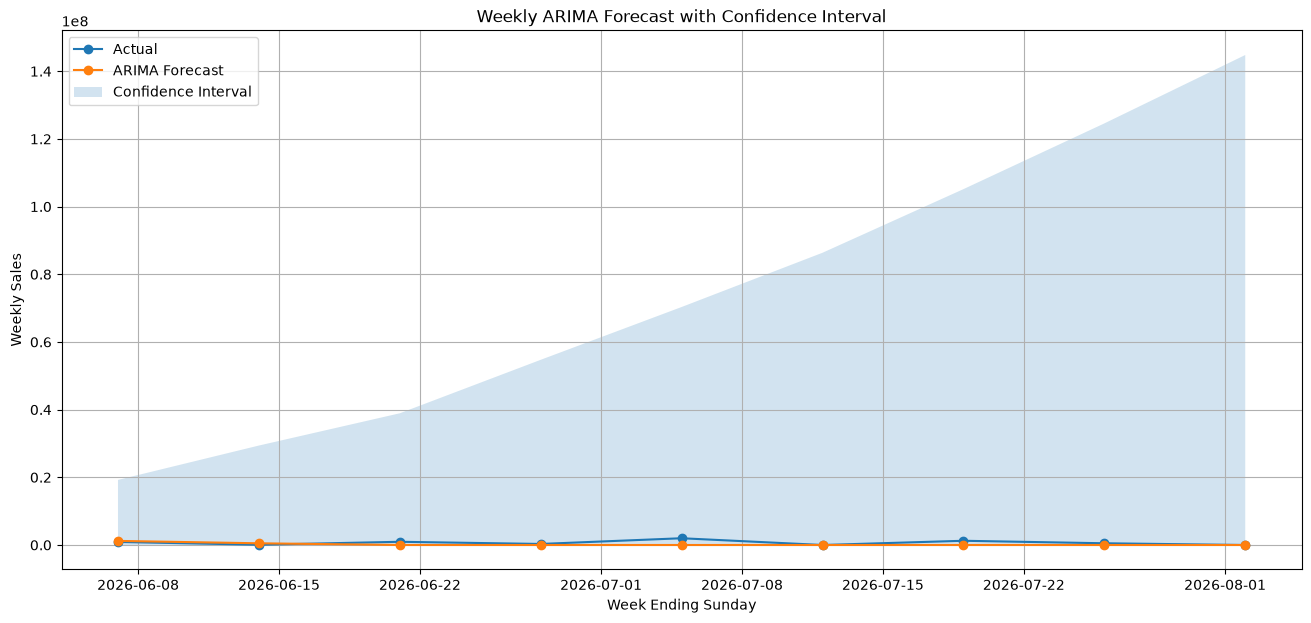

In [46]:
plt.figure(figsize=(16,7))
plt.plot(test.index, test, marker='o', label='Actual')
plt.plot(test.index, arima_predictions_clipped, marker='o', label='ARIMA Forecast')
plt.fill_between(test.index, test_confidence.iloc[:,0], test_confidence.iloc[:,1], alpha=0.2, label='Confidence Interval')
plt.title('Weekly ARIMA Forecast with Confidence Interval')
plt.xlabel('Week Ending Sunday')
plt.ylabel('Weekly Sales')
plt.legend()
plt.grid(True)
plt.show()


# Residual analysis

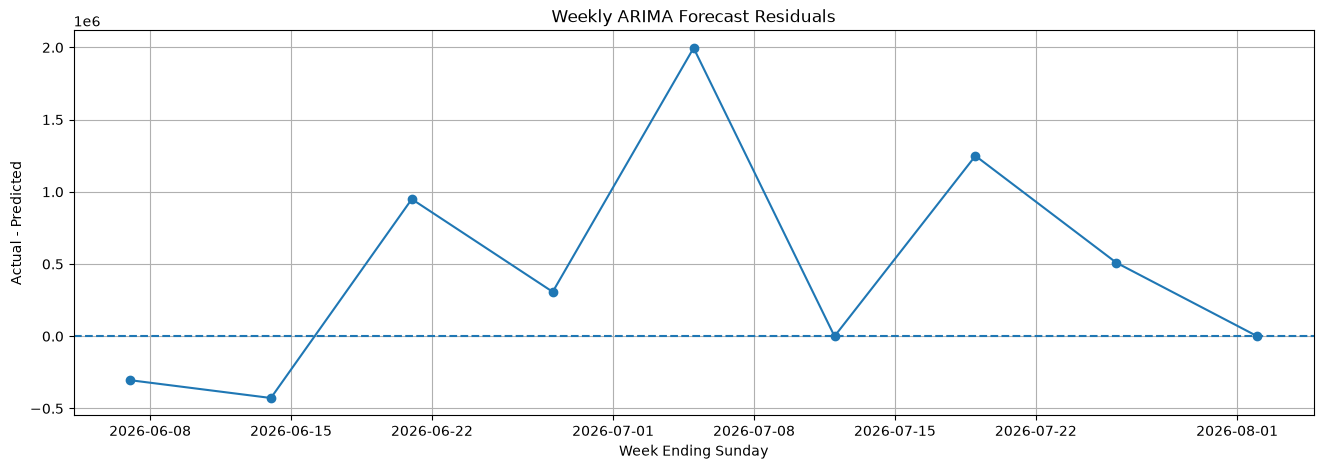

In [33]:
residuals = test - arima_predictions_clipped

plt.figure(figsize=(16,5))
plt.plot(residuals.index, residuals.values, marker='o')
plt.axhline(0, linestyle='--')
plt.title('Weekly ARIMA Forecast Residuals')
plt.xlabel('Week Ending Sunday')
plt.ylabel('Actual - Predicted')
plt.grid(True)
plt.show()


# Walk-forward validation

In [34]:
history = list(train.values)
walk_forward_predictions = []

for actual_value in test.values:
    fitted = ARIMA(history, order=(best_p, best_d, best_q)).fit()
    prediction = float(fitted.forecast(steps=1)[0])
    walk_forward_predictions.append(max(prediction, 0))
    history.append(actual_value)

walk_forward_predictions = pd.Series(walk_forward_predictions, index=test.index)
evaluate_model(test, walk_forward_predictions, 'Walk-Forward Weekly ARIMA')


Walk-Forward Weekly ARIMA
---------------------------------------------
Mean Absolute Error: 1,059,628.54
Root Mean Squared Error: 1,376,720.11
Weighted Absolute Percentage Error: 159.16%


## 22. Final metric comparison

In [35]:
all_metrics_df = pd.DataFrame([
    get_metrics(test, last_week_naive),
    get_metrics(test, four_week_mean_predictions),
    get_metrics(test, arima_predictions_clipped),
    get_metrics(test, walk_forward_predictions)
], index=[
    'Last-Week Naive',
    'Four-Week Mean',
    'ARIMA Multi-Step',
    'ARIMA Walk-Forward'
])

all_metrics_df.sort_values('WAPE')


,MAE,RMSE,WAPE
Last-Week Naive,5.835209e+05,6.966061e+05,87.648455
ARIMA Multi-Step,6.381013e+05,8.865950e+05,95.846774
ARIMA Walk-Forward,1.059629e+06,1.376720e+06,159.162780
Four-Week Mean,1.876585e+06,1.981319e+06,281.874635


## 23. Plot walk-forward ARIMA

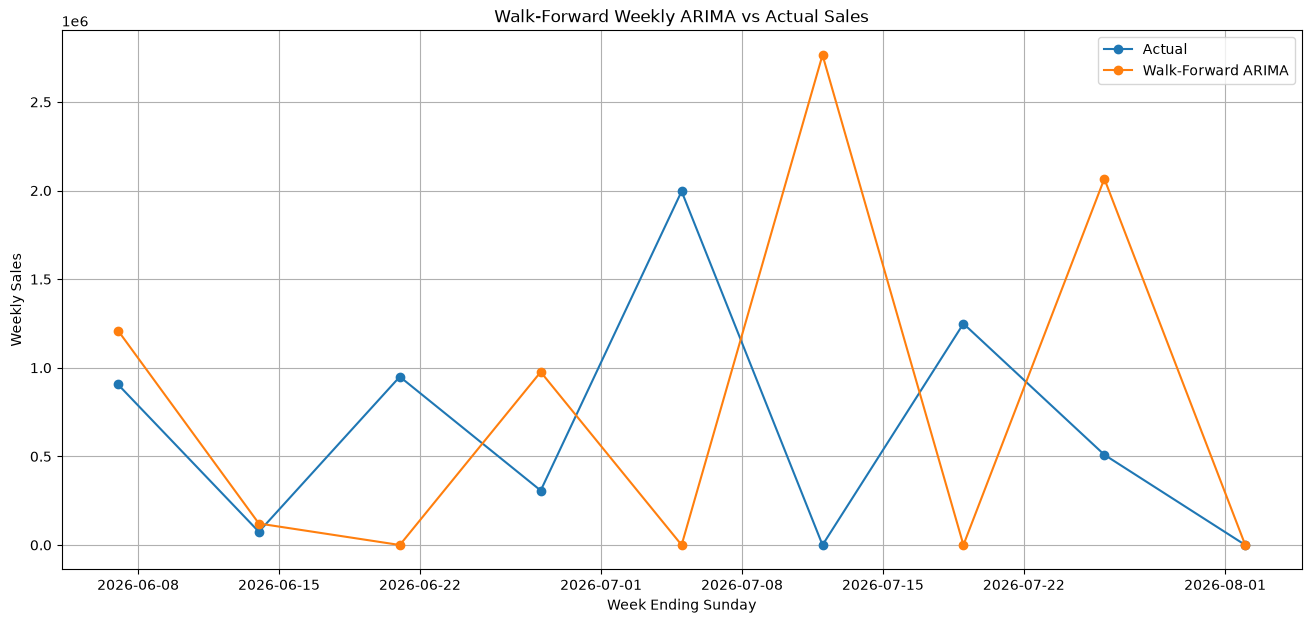

In [36]:
plt.figure(figsize=(16,7))
plt.plot(test.index, test, marker='o', label='Actual')
plt.plot(test.index, walk_forward_predictions, marker='o', label='Walk-Forward ARIMA')
plt.title('Walk-Forward Weekly ARIMA vs Actual Sales')
plt.xlabel('Week Ending Sunday')
plt.ylabel('Weekly Sales')
plt.legend()
plt.grid(True)
plt.show()


# Optional log-transformed ARIMA

If very large bulk-order weeks still dominate the model, this section trains ARIMA on `log(1 + weekly_sales)` and converts forecasts back with `exp(prediction) - 1`.


In [37]:
train_log = np.log1p(train)

log_results = []
for p, d, q in itertools.product(p_values, d_values, q_values):
    try:
        fitted = ARIMA(train_log, order=(p,d,q)).fit()
        log_results.append({'p':p, 'd':d, 'q':q, 'AIC':fitted.aic})
    except Exception:
        pass

log_results_df = pd.DataFrame(log_results).sort_values('AIC').reset_index(drop=True)
log_results_df.head(10)


c:\Users\adithyankg\OneDrive\Pictures\statistical_models\.venv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
c:\Users\adithyankg\OneDrive\Pictures\statistical_models\.venv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
c:\Users\adithyankg\OneDrive\Pictures\statistical_models\.venv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
c:\Users\adithyankg\OneDrive\Pictures\statistical_models\.venv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warning

,p,d,q,AIC
0,0,1,1,311.819243
1,0,1,2,313.386893
2,1,1,1,313.416389
3,3,1,0,313.667578
4,2,1,1,315.289840
5,0,1,3,315.382432
6,1,1,3,315.454517
7,1,1,2,315.490560
8,2,1,3,315.646354
9,3,1,1,315.666360


## 24. Fit and evaluate log-ARIMA

In [38]:
best_log = log_results_df.iloc[0]
log_p = int(best_log['p'])
log_d = int(best_log['d'])
log_q = int(best_log['q'])

log_result = ARIMA(train_log, order=(log_p,log_d,log_q)).fit()
log_forecast = log_result.get_forecast(steps=len(test))
log_predictions = np.expm1(log_forecast.predicted_mean)
log_predictions.index = test.index
log_predictions = log_predictions.clip(lower=0)

evaluate_model(test, log_predictions, 'Log-Transformed Weekly ARIMA')


Log-Transformed Weekly ARIMA
---------------------------------------------
Mean Absolute Error: 1,490,926.17
Root Mean Squared Error: 1,620,776.32
Weighted Absolute Percentage Error: 223.95%


## 25. Compare raw and log models

In [39]:
final_metrics_df = pd.DataFrame([
    get_metrics(test, last_week_naive),
    get_metrics(test, four_week_mean_predictions),
    get_metrics(test, arima_predictions_clipped),
    get_metrics(test, walk_forward_predictions),
    get_metrics(test, log_predictions)
], index=[
    'Last-Week Naive',
    'Four-Week Mean',
    'Raw ARIMA Multi-Step',
    'Raw ARIMA Walk-Forward',
    'Log ARIMA'
])

final_metrics_df.sort_values('WAPE')


,MAE,RMSE,WAPE
Last-Week Naive,5.835209e+05,6.966061e+05,87.648455
Raw ARIMA Multi-Step,6.381013e+05,8.865950e+05,95.846774
Raw ARIMA Walk-Forward,1.059629e+06,1.376720e+06,159.162780
Log ARIMA,1.490926e+06,1.620776e+06,223.946358
Four-Week Mean,1.876585e+06,1.981319e+06,281.874635


# Final model on all complete weekly history

In [40]:
full_weekly_series = weekly_sales.copy()
final_model = ARIMA(full_weekly_series, order=(best_p,best_d,best_q))
final_result = final_model.fit()
print(final_result.summary())


                               SARIMAX Results                                
Dep. Variable:      daily_sales_total   No. Observations:                   82
Model:                 ARIMA(2, 2, 0)   Log Likelihood               -1400.673
Date:                Mon, 10 Aug 2026   AIC                           2807.347
Time:                        10:06:28   BIC                           2814.493
Sample:                    01-12-2025   HQIC                          2810.212
                         - 08-02-2026                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.7482      0.046    -16.134      0.000      -0.839      -0.657
ar.L2         -0.5412      0.032    -16.996      0.000      -0.604      -0.479
sigma2      7.507e+13   2.94e-16   2.56e+29      0.0

# Forecast the next 12 weeks

In [41]:
future_forecast = final_result.get_forecast(steps=12)
future_mean = future_forecast.predicted_mean.clip(lower=0)
future_confidence = future_forecast.conf_int()

future_dates = pd.date_range(
    start=full_weekly_series.index.max() + pd.Timedelta(weeks=1),
    periods=12,
    freq='W-SUN'
)

future_df = pd.DataFrame({
    'week_ending': future_dates,
    'predicted_weekly_sales': future_mean.values,
    'lower_bound': future_confidence.iloc[:,0].values,
    'upper_bound': future_confidence.iloc[:,1].values
})

future_df['lower_bound'] = future_df['lower_bound'].clip(lower=0)
future_df


,week_ending,predicted_weekly_sales,lower_bound,upper_bound
0,2026-08-09,394724.347864,0.0,1.737652e+07
1,2026-08-16,0.000000,0.0,2.719598e+07
2,2026-08-23,0.000000,0.0,3.722092e+07
3,2026-08-30,0.000000,0.0,5.250510e+07
4,2026-09-06,0.000000,0.0,6.765115e+07
5,2026-09-13,0.000000,0.0,8.352079e+07
6,2026-09-20,0.000000,0.0,1.017323e+08
7,2026-09-27,0.000000,0.0,1.205567e+08
8,2026-10-04,0.000000,0.0,1.402566e+08
9,2026-10-11,0.000000,0.0,1.613483e+08


## 26. Plot future weekly forecast

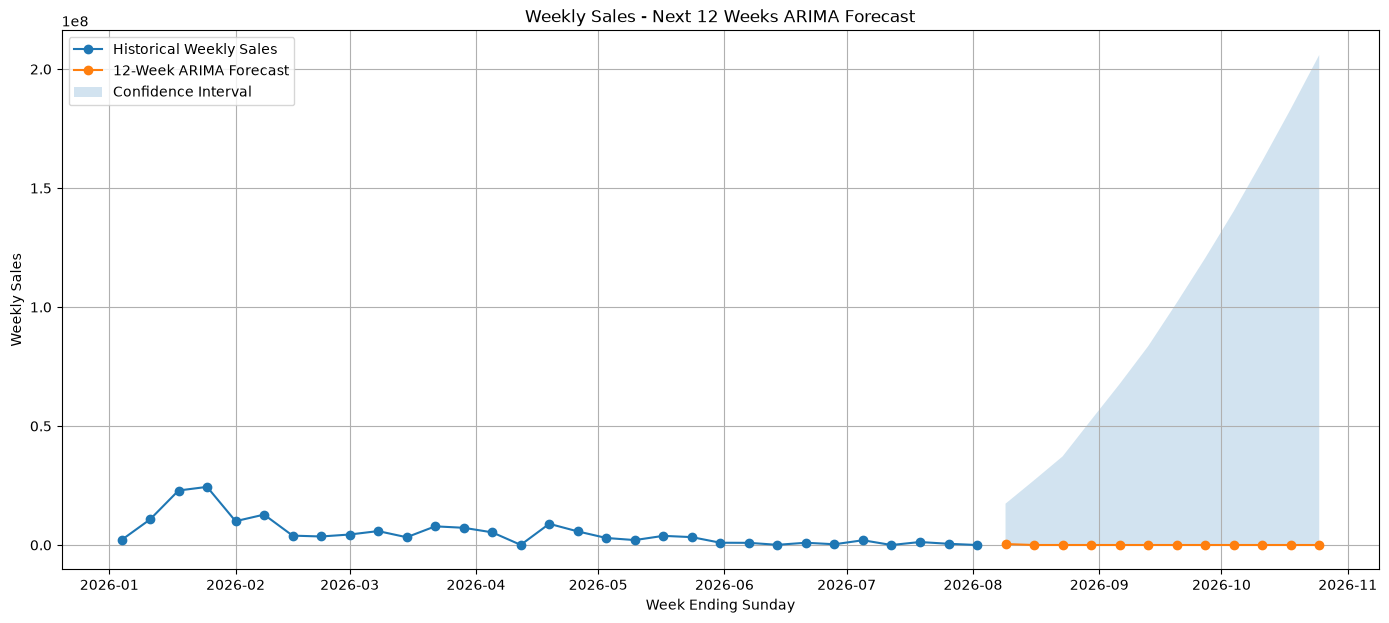

In [42]:
plt.figure(figsize=(17,7))
recent_history = full_weekly_series.loc['2026-01-01':]

plt.plot(recent_history.index, recent_history.values, marker='o', label='Historical Weekly Sales')
plt.plot(future_df['week_ending'], future_df['predicted_weekly_sales'], marker='o', label='12-Week ARIMA Forecast')
plt.fill_between(future_df['week_ending'], future_df['lower_bound'], future_df['upper_bound'], alpha=0.2, label='Confidence Interval')
plt.title('Weekly Sales - Next 12 Weeks ARIMA Forecast')
plt.xlabel('Week Ending Sunday')
plt.ylabel('Weekly Sales')
plt.legend()
plt.grid(True)
plt.show()


# Export outputs

In [43]:
weekly_export = weekly_sales.rename('weekly_sales_total').reset_index()
weekly_export = weekly_export.rename(columns={'sale_date':'week_ending'})
weekly_export.to_csv('../input/weekly_sales_history.csv', index=False)

future_df.to_csv('arima_weekly_12_week_forecast.csv', index=False)

final_result.save('arima_weekly_sales_model.pkl')

print('Saved: ../input/weekly_sales_history.csv')
print('Saved: arima_weekly_12_week_forecast.csv')
print('Saved: arima_weekly_sales_model.pkl')


Saved: ../input/weekly_sales_history.csv
Saved: arima_weekly_12_week_forecast.csv
Saved: arima_weekly_sales_model.pkl


## Load the saved model later

In [44]:
loaded_model = ARIMAResults.load('arima_weekly_sales_model.pkl')
print('Weekly ARIMA model loaded successfully.')


Weekly ARIMA model loaded successfully.


# How to judge whether weekly ARIMA is useful

Use the **test-period metrics**, especially Weighted Absolute Percentage Error.

If ARIMA beats the simple baselines, weekly aggregation is helping.

If the baselines still beat ARIMA, that means the weekly sales process may still need another model or more explanatory variables.

For true product-demand forecasting, the next step should usually be weekly **Stock Keeping Unit (SKU)-level quantity forecasting** from `sale_order_line`, rather than only total revenue.
